In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report



In [2]:
#!pip install pandas numpy matplotlib seaborn
#!pip install scikit-learn ucimlrepo joblib

In [3]:
#import sys
#!{sys.executable} -m pip install ucimlrepo

In [4]:
#nstall the missing library
#!pip install ucimlrepo

In [5]:
#%pip install ucimlrepo

In [6]:
import ucimlrepo

print("Library installed successfully!")

Library installed successfully!


In [7]:
# Load the dataset
#



# Fetch the Credit Card Clients dataset
dataset = fetch_ucirepo(id=350)

# Separate features and target
X = dataset.data.features
y = dataset.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

# Display first five rows
print(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Save dataset as CSV
df.to_csv("financial_risk_dataset.csv", index=False)

print("Dataset saved successfully!")

       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X15    X16    X17  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...      0      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   3272   3455   3261   
2   90000   2   2   2  34   0   0   0   0    0  ...  14331  14948  15549   
3   50000   2   2   1  37   0   0   0   0    0  ...  28314  28959  29547   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  20940  19146  19131   

    X18    X19    X20   X21   X22   X23  Y  
0     0    689      0     0     0     0  1  
1     0   1000   1000  1000     0  2000  1  
2  1518   1500   1000  1000  1000  5000  0  
3  2000   2019   1200  1100  1069  1000  0  
4  2000  36681  10000  9000   689   679  0  

[5 rows x 24 columns]
Dataset Shape: (30000, 24)
Dataset saved successfully!


In [8]:
#Dataset Understanding
# Dataset Information
df.info()

# Statistical description
print(df.describe())

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print(df.duplicated().sum())

# Check column names
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int64
 23  Y       300

In [9]:
#Data Preprocessing
# Remove ID
if 'ID' in df.columns:
    df.drop('ID', axis=1, inplace=True)

# Separate input and target
X = df.drop('Y', axis=1)
y = df['Y']

# Check target distribution
print(y.value_counts())

0    23364
1     6636
Name: Y, dtype: int64


In [10]:
# Check all column names
print("Column Names:")
print(df.columns.tolist())

# Display first five rows
print(df.head())

Column Names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']
       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X15    X16    X17  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...      0      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   3272   3455   3261   
2   90000   2   2   2  34   0   0   0   0    0  ...  14331  14948  15549   
3   50000   2   2   1  37   0   0   0   0    0  ...  28314  28959  29547   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  20940  19146  19131   

    X18    X19    X20   X21   X22   X23  Y  
0     0    689      0     0     0     0  1  
1     0   1000   1000  1000     0  2000  1  
2  1518   1500   1000  1000  1000  5000  0  
3  2000   2019   1200  1100  1069  1000  0  
4  2000  36681  10000  9000   689   679  0  

[5 rows x 24 columns]


In [11]:
# Display all column names
print(df.columns.tolist())

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [12]:
# check whether age is there or not
print('AGE' in df.columns)

False


In [13]:
# Find columns containing AGE
for col in df.columns:
    if 'AGE' in str(col).upper():
        print("Age column found:", col)

In [14]:
# Rename dataset columns

df.columns = [
    'LIMIT_BAL',
    'SEX',
    'EDUCATION',
    'MARRIAGE',
    'AGE',
    'PAY_0',
    'PAY_2',
    'PAY_3',
    'PAY_4',
    'PAY_5',
    'PAY_6',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6',
    'default.payment.next.month'
]

print(df.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


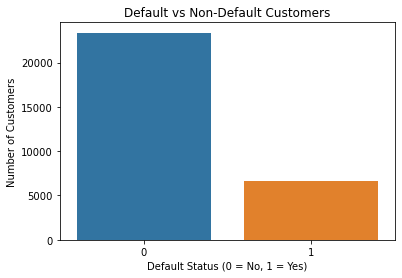

In [15]:
#Exploratory Data Analysis (EDA) and graphs
#Graph 1: Default vs Non-default customers


plt.figure(figsize=(6,4))

sns.countplot(x=y)

plt.title("Default vs Non-Default Customers")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

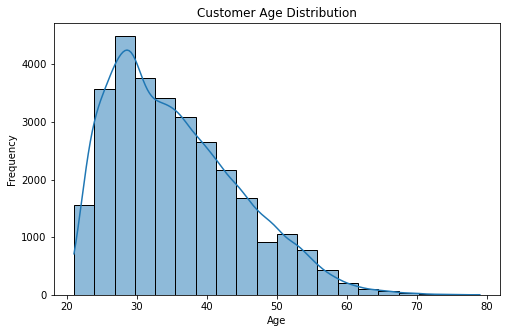

In [16]:
# Graph 2: Age distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(data=df, x='AGE', bins=20, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

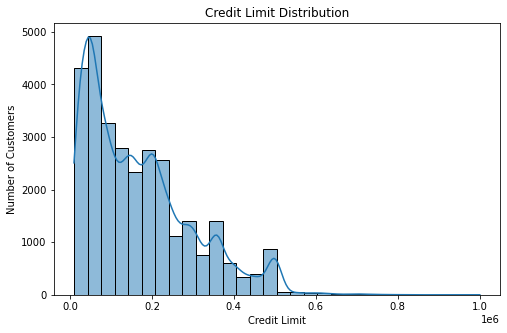

In [17]:
#Graph 3: Credit limit distribution
plt.figure(figsize=(8,5))

sns.histplot(df['LIMIT_BAL'], bins=30, kde=True)

plt.title("Credit Limit Distribution")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Customers")

plt.show()

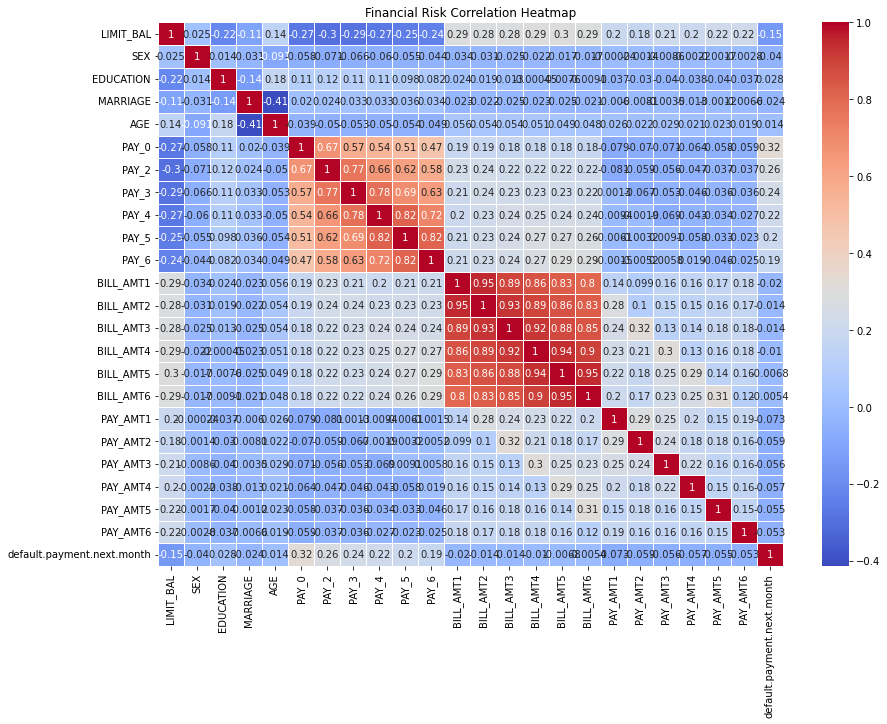

In [18]:

# Graph 4: Correlation Heatmap

plt.figure(figsize=(14,10))

# Select only numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    linewidths=0.5
)

plt.title("Financial Risk Correlation Heatmap")
plt.show()

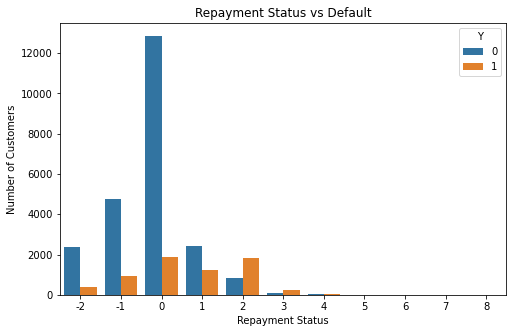

In [19]:
#Graph 5: Repayment status
plt.figure(figsize=(8,5))

sns.countplot(x=df['PAY_0'], hue=y)

plt.title("Repayment Status vs Default")
plt.xlabel("Repayment Status")
plt.ylabel("Number of Customers")

plt.show()

In [21]:
#Feature selection


# Remove demographic columns for this model
columns_to_remove = [
    'SEX', 'AGE', 'EDUCATION', 'MARRIAGE'
]

X = X.drop(
    columns=columns_to_remove,
    errors='ignore'
)

print(X.head())

       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X14    X15    X16  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...    689      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   2682   3272   3455   
2   90000   2   2   2  34   0   0   0   0    0  ...  13559  14331  14948   
3   50000   2   2   1  37   0   0   0   0    0  ...  49291  28314  28959   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  35835  20940  19146   

     X17   X18    X19    X20   X21   X22   X23  
0      0     0    689      0     0     0     0  
1   3261     0   1000   1000  1000     0  2000  
2  15549  1518   1500   1000  1000  1000  5000  
3  29547  2000   2019   1200  1100  1069  1000  
4  19131  2000  36681  10000  9000   689   679  

[5 rows x 23 columns]


In [22]:
#Train and test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24000, 23)
Testing data: (6000, 23)


In [23]:
#Apply Machine Learning algorithms

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.679500   0.367083  0.620196  0.461194  0.708080
1        Decision Tree  0.776000   0.494276  0.553127  0.522048  0.762516
2        Random Forest  0.814833   0.652975  0.347400  0.453517  0.756322


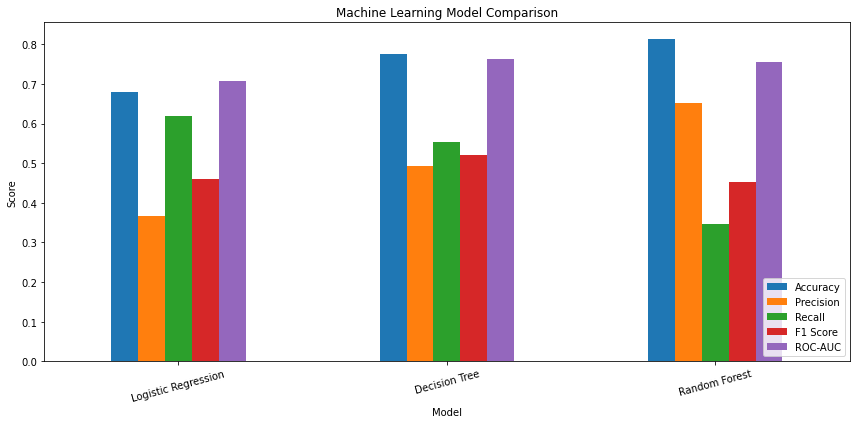

In [24]:
#Model comparison graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12,6))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

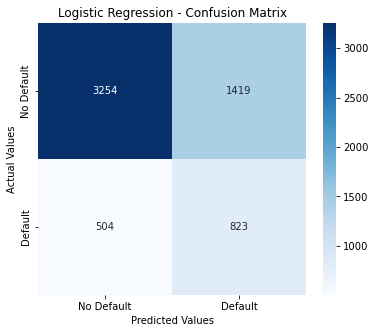

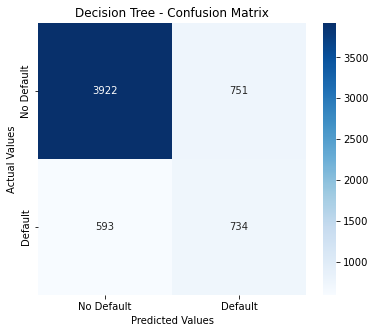

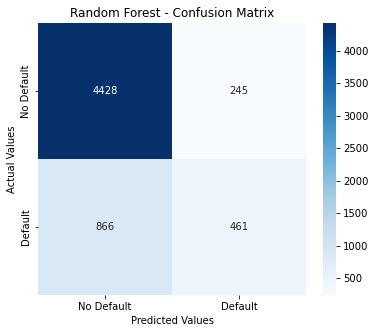

In [25]:
# Store model performance



for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Display confusion matrix
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Default', 'Default'],
        yticklabels=['No Default', 'Default']
    )

    plt.title(name + ' - Confusion Matrix')
    plt.xlabel('Predicted Values')
    plt.ylabel('Actual Values')
    plt.show()

   

In [26]:
results = []
for name, model in models.items():
     # Calculate performance metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.65      0.35      0.45      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.80      0.81      0.79      6000


 Decision Tree
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.65      0.35      0.45      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.80      0.81      0.79      6000


 Random Forest
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.65      0.35      0.45      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0

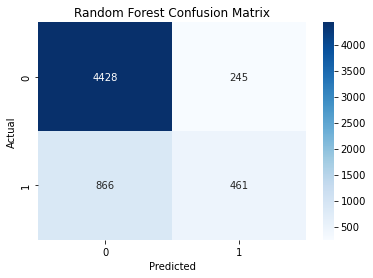

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.65      0.35      0.45      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.80      0.81      0.79      6000



In [27]:
#Confusion matrix and classification report


best_model = models["Random Forest"]

predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, predictions))

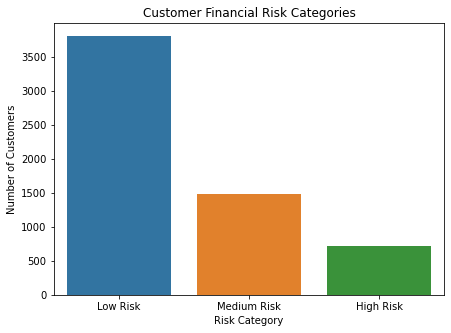

In [29]:
#Graph 6: Risk category distribution

plt.figure(figsize=(7,5))

sns.countplot(
    x=risk_results["Risk Category"],
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Financial Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
#Early warning risk classification

# Predict default probability
risk_probability = best_model.predict_proba(X_test)[:, 1]

# Create risk categories
def risk_category(probability):

    if probability < 0.20:
        return "Low Risk"

    elif probability < 0.50:
        return "Medium Risk"

    else:
        return "High Risk"

risk_predictions = [
    risk_category(p) for p in risk_probability
]

# Create result dataframe
risk_results = pd.DataFrame({
    "Actual Default": y_test.values,
    "Default Probability": risk_probability,
    "Risk Category": risk_predictions
})

print(risk_results.head(10))

risk_results.to_csv(
    "financial_risk_predictions.csv",
    index=False
)

   Actual Default  Default Probability Risk Category
0               0                0.085      Low Risk
1               0                0.145      Low Risk
2               0                0.200   Medium Risk
3               1                0.135      Low Risk
4               0                0.010      Low Risk
5               0                0.305   Medium Risk
6               0                0.090      Low Risk
7               0                0.010      Low Risk
8               0                0.170      Low Risk
9               0                0.060      Low Risk


In [ ]:
#Save the trained model
import joblib

joblib.dump(
    best_model,
    "financial_risk_model.pkl"
)

joblib.dump(
    list(X_train.columns),
    "feature_columns.pkl"
)

print("Model saved successfully!")

In [ ]:
#this trained models are saved for future purpose as we can build frontend based appliactions based on this trained model